<div style="text-align: center;" >
<h1 style="margin-top: 0.2em; margin-bottom: 0.1em;">Feature Engineering and Machine Learning</h1>

</div>
<br>
This notebook is the final stage of a four-part pipeline (`01_launch_data_collection.py` -> `02_weather_data_collection.py` -> `03_data_cleaning.py` -> this notebook). It engineers features from historical orbital launch and weather data, then trains and compares three classifiers (Logistic Regression, Random Forest, XGBoost) to predict whether a launch will succeed or fail.


## 1.0 Imports and Configuration

Standard data manipulation, visualization, and modelling libraries. A fixed random seed is set once here so the train/test split, the feature engineering thresholds, and all three models behave reproducibly across runs.


In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, average_precision_score, auc, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

np.random.seed(111)


## 1.1 Helper Functions

This section defines every reusable function used later in the notebook: feature-engineering helpers that get applied identically to the train and test sets, and model-evaluation helpers used across all three classifiers. Centralizing them here means each transformation's logic lives in exactly one place, rather than being copy-pasted once per split (which is how train/test logic quietly drifts out of sync).


In [38]:
def add_time_features(launch_dataset):
    """
    Derive calendar-based features from the launch window start time:
    year, month, day of week, and a weekend flag.

    Parameters
    ----------
    launch_dataset : pandas.DataFrame
        Must contain a `window_start` column (string or datetime-like).

    Returns
    -------
    pandas.DataFrame
    """
    launch_dataset["window_start"] = pd.to_datetime(launch_dataset["window_start"], errors='coerce')

    launch_dataset["year"] = launch_dataset["window_start"].dt.year
    launch_dataset["month"] = launch_dataset["window_start"].dt.month
    launch_dataset["weekday"] = launch_dataset["window_start"].dt.weekday
    launch_dataset["is_weekend"] = launch_dataset["weekday"].isin([5, 6]).astype(int)

    return launch_dataset


def encode_binary_target(launch_dataset):
    """
    Collapse the `status.abbrev` launch outcome into a binary target.

    Failures and partial failures are combined into a single positive
    class (1) because there are too few of either to model separately;
    successes become the negative class (0).

    Parameters
    ----------
    launch_dataset : pandas.DataFrame
        Must contain a `status.abbrev` column.

    Returns
    -------
    pandas.DataFrame
        Same DataFrame with a new `launch_outcome` column and
        `status.abbrev` dropped.
    """
    launch_dataset["launch_outcome"] = np.where(launch_dataset["status.abbrev"] == "Success", 0, 1)
    return launch_dataset.drop(columns="status.abbrev")


In [39]:
# Launches by a rocket/pad/agency with fewer than this many prior orbital
# attempts are flagged as "new". Threshold follows Hussein et al. (2025).
NEW_ENTITY_THRESHOLD = 10

# Ordinal difficulty rank per target orbit (1 = easiest sub-orbital hop,
# 6 = hardest deep-space/Lagrange-point orbits), based on the European
# Space Agency's orbit classifications.
ORBIT_DIFFICULTY_MAP = {
    'Sub': 1,
    'LEO': 2, 'VLEO': 2, 'PO': 2,
    'SSO': 3, 'Helio-N/A': 3,
    'MEO': 4, 'Elliptical': 4, 'HEO': 4,
    'GTO': 5, 'GSTO': 5, 'Super-GTO': 5,
    'GEO': 6, 'Direct-GEO': 6, 'GSO': 6, 'LO': 6, 'L1-point': 6, 'L2': 6
}

# Near-duplicate/redundant weather columns dropped after the extreme-
# weather flags below are derived from their non-redundant counterparts.
WEATHER_COLUMNS_TO_DROP = [
    "weather.daily.wind_direction_10m_dominant", "weather.daily.precipitation_sum",
    "weather.daily.precipitation_hours", "weather.daily.cloud_cover_min",
    "weather.daily.weather_code", "weather.daily.relative_humidity_2m_mean",
    "weather.daily.relative_humidity_2m_min", "weather.daily.surface_pressure_mean",
    "weather.daily.surface_pressure_min", "weather.daily.winddirection_10m_dominant",
    "weather.daily.wind_gusts_10m_mean", "weather.daily.wind_speed_10m_mean",
    "weather.daily.wind_speed_10m_min", "weather.daily.wind_gusts_10m_min",
    "weather.daily.snowfall_water_equivalent_sum", "weather.daily.pressure_msl_mean",
    "weather.daily.pressure_msl_max", "weather.daily.pressure_msl_min",
    "weather.daily.temperature_2m_mean"
]

# High-cardinality categorical columns; rare categories get collapsed into
# "Other" before one-hot encoding.
CATEGORICAL_COLUMNS_TO_COLLAPSE = [
    "launch_service_provider.name", "launch_service_provider.type",
    "rocket.configuration.family", "mission.type", "pad.location.name", "pad.country_code"
]
RARE_CATEGORY_THRESHOLD_PCT = 0.01


In [40]:
def add_log_launch_count_features(df):
    """
    Add log1p-transformed agency/pad launch counts.

    Log-transforming means early launches by a new agency or pad shift
    the feature more than later launches by an established one, capturing
    diminishing returns to experience.
    """
    df["log_agency_launches"] = np.log1p(df["agency_launch_attempt_count"])
    df["log_pad_launches"] = np.log1p(df["pad_launch_attempt_count"])
    return df


def add_new_entity_flags(df, threshold=NEW_ENTITY_THRESHOLD):
    """
    Flag launches that use a rocket, pad, or agency with fewer than
    `threshold` prior orbital launch attempts.
    """
    df["new_rocket_flag"] = (df["orbital_launch_attempt_count"] < threshold).astype(int)
    df["new_pad_flag"] = (df["pad_launch_attempt_count"] < threshold).astype(int)
    df["new_agency_flag"] = (df["agency_launch_attempt_count"] < threshold).astype(int)
    return df


def add_rocket_maturity_feature(df):
    """
    Add a cumulative per-rocket-model launch count and its log1p
    transform, then drop the now-unneeded rocket configuration id.

    The count is computed within whichever DataFrame it's applied to (in
    chronological row order, since rows are already date-sorted), so it
    reflects experience accumulated up to that point.
    """
    df["rocket_model_experience"] = df.groupby("rocket.configuration.id").cumcount() + 1
    df["rocket_maturity"] = np.log1p(df["rocket_model_experience"])
    return df.drop(columns="rocket.configuration.id")


def add_orbit_difficulty_feature(df):
    """
    Map each launch's target orbit to its ordinal difficulty rank (see
    `ORBIT_DIFFICULTY_MAP`). Missing/unmapped values default to 2 (LEO),
    the most common orbit.
    """
    df["orbit_difficulty"] = df["mission.orbit.abbrev"].map(ORBIT_DIFFICULTY_MAP).fillna(2)
    return df.drop(columns=["mission.orbit.abbrev"])


In [41]:
def compute_extreme_weather_thresholds(X_train):
    """
    Compute the 90th/10th percentile weather thresholds used to flag
    extreme conditions, using ONLY the training set so information from
    the test period can't leak into how the features are defined.

    Returns
    -------
    dict
        Keys: "wind_speed_p90", "rain_p90", "temp_max_p90", "temp_min_p10".
    """
    return {
        "wind_speed_p90": X_train["weather.daily.wind_speed_10m_max"].quantile(0.9),
        "rain_p90": X_train["weather.daily.rain_sum"].quantile(0.9),
        "temp_max_p90": X_train["weather.daily.temperature_2m_max"].quantile(0.9),
        "temp_min_p10": X_train["weather.daily.temperature_2m_min"].quantile(0.1),
    }


def add_extreme_weather_flags(df, thresholds):
    """
    Add binary flags for high wind, high rain, and extreme temperature,
    using pre-computed `thresholds` (see `compute_extreme_weather_thresholds`)
    so the same cutoffs are applied consistently to train and test data.
    """
    df["high_wind_flag"] = (df["weather.daily.wind_speed_10m_max"] > thresholds["wind_speed_p90"]).astype(int)
    df["high_rain_flag"] = (df["weather.daily.rain_sum"] > thresholds["rain_p90"]).astype(int)
    df["extreme_temp_flag"] = (
        (df["weather.daily.temperature_2m_max"] > thresholds["temp_max_p90"]) |
        (df["weather.daily.temperature_2m_min"] < thresholds["temp_min_p10"])
    ).astype(int)
    return df


def collapse_rare_categories(X_train, X_test, columns, threshold_pct=RARE_CATEGORY_THRESHOLD_PCT):
    """
    Collapse infrequent categories (below `threshold_pct` of training
    rows) into "Other", to reduce cardinality and avoid overly sparse
    one-hot encoded columns.

    Rare categories are identified using ONLY the training set, then the
    same categories are collapsed in both train and test.
    """
    min_count = int(threshold_pct * len(X_train))

    for col in columns:
        category_counts = X_train[col].value_counts()
        rare_categories = category_counts[category_counts < min_count].index

        X_train[col] = X_train[col].replace(rare_categories, "Other")
        X_test[col] = X_test[col].replace(rare_categories, "Other")

    return X_train, X_test


def scale_and_encode_features(X_train, X_test, categorical_columns):
    """
    Standard-scale numeric columns (fit on train only) and one-hot encode
    categorical columns, then align test columns to match train (in case
    a category present in one split is absent in the other).
    """
    numeric_columns = X_train.select_dtypes(include=['float64', 'int64', 'int32']).columns

    scaler = StandardScaler()
    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

    X_train_scaled[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
    X_test_scaled[numeric_columns] = scaler.transform(X_test[numeric_columns])

    X_train_scaled = pd.get_dummies(X_train_scaled, columns=categorical_columns, drop_first=True)
    X_test_scaled = pd.get_dummies(X_test_scaled, columns=categorical_columns, drop_first=True)

    # Align columns on train and test (handles a category that only shows
    # up in one of the two splits)
    X_test_scaled = X_test_scaled.reindex(columns=X_train_scaled.columns, fill_value=0)

    return X_train_scaled, X_test_scaled


In [42]:
def engineer_post_split_features(X_train, X_test):
    """
    Run the full post-split feature engineering pipeline on the train and
    test sets, fitting any data-derived parameters (quantile thresholds,
    rare-category lists, the scaler) on `X_train` only and then applying
    them identically to `X_test`.

    Keeping this logic in one function -- rather than duplicating each
    step inline for both splits -- means a bug fix or a new feature only
    needs to be written once, and train/test can't silently drift apart.

    Parameters
    ----------
    X_train, X_test : pandas.DataFrame
        Feature matrices produced by the chronological train/test split,
        before any post-split feature engineering.

    Returns
    -------
    (pandas.DataFrame, pandas.DataFrame)
        Fully engineered, scaled, and one-hot encoded (X_train, X_test).
    """
    X_train = add_log_launch_count_features(X_train)
    X_test = add_log_launch_count_features(X_test)

    X_train = add_new_entity_flags(X_train)
    X_test = add_new_entity_flags(X_test)

    X_train = add_rocket_maturity_feature(X_train)
    X_test = add_rocket_maturity_feature(X_test)

    weather_thresholds = compute_extreme_weather_thresholds(X_train)
    X_train = add_extreme_weather_flags(X_train, weather_thresholds)
    X_test = add_extreme_weather_flags(X_test, weather_thresholds)

    X_train = X_train.drop(columns=WEATHER_COLUMNS_TO_DROP)
    X_test = X_test.drop(columns=WEATHER_COLUMNS_TO_DROP)

    X_train = add_orbit_difficulty_feature(X_train)
    X_test = add_orbit_difficulty_feature(X_test)

    X_train, X_test = collapse_rare_categories(X_train, X_test, CATEGORICAL_COLUMNS_TO_COLLAPSE)

    X_train_scaled, X_test_scaled = scale_and_encode_features(X_train, X_test, CATEGORICAL_COLUMNS_TO_COLLAPSE)

    return X_train_scaled, X_test_scaled


## 1.2 Load Dataset

Loading the dataset cleaned in `03_data_cleaning.py`.


In [43]:
launch_dataset = pd.read_csv("launch_dataset_cleaned.csv")
launch_dataset.head()


,id,name,net,window_end,window_start,orbital_launch_attempt_count,location_launch_attempt_count,pad_launch_attempt_count,agency_launch_attempt_count,orbital_launch_attempt_count_year,...,weather.daily.winddirection_10m_dominant,weather.daily.wind_gusts_10m_mean,weather.daily.wind_speed_10m_mean,weather.daily.wind_speed_10m_min,weather.daily.wind_gusts_10m_min,weather.daily.snowfall_water_equivalent_sum,weather.daily.pressure_msl_mean,weather.daily.pressure_msl_max,weather.daily.pressure_msl_min,weather.daily.temperature_2m_mean
0,4f880a82-20f7-4892-a8db-24ab4f07aae4,GSLV Mk II | GSAT-14,2014-01-05T10:48:00Z,2014-01-05 10:48:00+00:00,2014-01-05 10:48:00+00:00,5350.0,41,9,40,1.0,...,42.0,21.2,12.5,9.2,14.0,0.0,1012.0,1014.8,1010.0,24.5
1,5a1f68d5-dd06-47d0-bc53-001c516794ed,Falcon 9 v1.1 | Thaicom-6,2014-01-06T22:06:00Z,2014-01-06 22:06:00+00:00,2014-01-06 22:06:00+00:00,5351.0,704,62,13,2.0,...,249.0,28.2,17.5,7.9,15.1,0.0,1015.8,1020.5,1014.4,20.1
2,262f0534-c5a3-4956-b268-756173baf36b,Antares 120 | Cygnus CRS Orb-1 (S.S. C. Gordon...,2014-01-09T18:07:05Z,2014-01-09 18:07:05+00:00,2014-01-09 18:07:05+00:00,5352.0,57,4,70,3.0,...,61.0,17.2,9.4,4.0,11.5,0.0,1035.2,1037.3,1033.3,1.6
3,0c5b798d-2ec4-4e3e-94c0-f2f157231949,SpaceShipTwo | VSS Enterprise PF03,2014-01-10T12:00:00Z,2014-01-10 12:00:00+00:00,2014-01-10 12:00:00+00:00,0.0,51,32,32,0.0,...,304.0,30.7,13.3,11.5,26.3,0.0,1020.5,1022.9,1017.2,7.1
4,ed7f2111-d4fc-4193-9219-bf4d43f6e1db,SpaceShipTwo | VSS Enterprise GF28,2014-01-17T12:00:00Z,2014-01-17 12:00:00+00:00,2014-01-17 12:00:00+00:00,0.0,52,33,33,0.0,...,40.0,25.6,11.3,6.9,18.7,0.0,1022.2,1024.1,1019.8,12.6


## 1.3 Pre-Split Feature Engineering

Time-based features and the binary target are derived before the train/test split, since both are deterministic, row-by-row transformations with no risk of leaking information across the split boundary unlike the threshold and scaler-based features in section 1.6, which must be fit on the training set only.


In [44]:
launch_dataset = add_time_features(launch_dataset)


In [45]:
print(launch_dataset.isna().sum().to_string())
print(launch_dataset.dtypes.to_string())


id                                             0
name                                           0
net                                            0
window_end                                     0
window_start                                   0
orbital_launch_attempt_count                   0
location_launch_attempt_count                  0
pad_launch_attempt_count                       0
agency_launch_attempt_count                    0
orbital_launch_attempt_count_year              0
location_launch_attempt_count_year             0
pad_launch_attempt_count_year                  0
agency_launch_attempt_count_year               0
type                                           0
status.abbrev                                  0
launch_service_provider.id                     0
launch_service_provider.name                   0
launch_service_provider.type                   0
rocket.id                                      0
rocket.configuration.id                        0
rocket.configuration

In [46]:
# Check class distribution before collapsing into a binary target
print(launch_dataset["status.abbrev"].value_counts())

launch_dataset = encode_binary_target(launch_dataset)

# We have roughly 95% success and 5% failure
print(launch_dataset["launch_outcome"].value_counts())


status.abbrev
Success            1839
Failure              88
Partial Failure      17
Name: count, dtype: int64
launch_outcome
0    1839
1     105
Name: count, dtype: int64


In [47]:
# Columns not used for modelling: identifiers, raw timestamps already
# captured by the derived time features, and columns that would leak
# the launch's identity rather than provide generalizable signal.
cols_to_remove = [
    "id", "name", "net", "window_start", "window_end", "window_end_date", "type",
    "launch_service_provider.id", "rocket.id", "rocket.configuration.name", "pad.id", "pad.name",
    "pad.location.id", "pad.latitude", "pad.longitude", "pad.location.country_code",
    "rocket.configuration.full_name", "rocket.configuration.variant"
]
launch_dataset = launch_dataset.drop(columns=cols_to_remove)


In [48]:
X = launch_dataset.loc[:, "orbital_launch_attempt_count":"is_weekend"]
y = launch_dataset["launch_outcome"]

X.head()


,orbital_launch_attempt_count,location_launch_attempt_count,pad_launch_attempt_count,agency_launch_attempt_count,orbital_launch_attempt_count_year,location_launch_attempt_count_year,pad_launch_attempt_count_year,agency_launch_attempt_count_year,launch_service_provider.name,launch_service_provider.type,...,weather.daily.wind_gusts_10m_min,weather.daily.snowfall_water_equivalent_sum,weather.daily.pressure_msl_mean,weather.daily.pressure_msl_max,weather.daily.pressure_msl_min,weather.daily.temperature_2m_mean,year,month,weekday,is_weekend
0,5350.0,41,9,40,1.0,1,1,1,Indian Space Research Organization,Government,...,14.0,0.0,1012.0,1014.8,1010.0,24.5,2014,1,6,1
1,5351.0,704,62,13,2.0,1,1,1,SpaceX,Commercial,...,15.1,0.0,1015.8,1020.5,1014.4,20.1,2014,1,0,0
2,5352.0,57,4,70,3.0,1,1,1,Orbital Sciences Corporation,Commercial,...,11.5,0.0,1035.2,1037.3,1033.3,1.6,2014,1,3,0
3,0.0,51,32,32,0.0,1,1,1,Virgin Galactic,Private,...,26.3,0.0,1020.5,1022.9,1017.2,7.1,2014,1,4,0
4,0.0,52,33,33,0.0,2,2,2,Virgin Galactic,Private,...,18.7,0.0,1022.2,1024.1,1019.8,12.6,2014,1,4,0


In [49]:
X.describe()


,orbital_launch_attempt_count,location_launch_attempt_count,pad_launch_attempt_count,agency_launch_attempt_count,orbital_launch_attempt_count_year,location_launch_attempt_count_year,pad_launch_attempt_count_year,agency_launch_attempt_count_year,rocket.configuration.id,pad.location.total_launch_count,...,weather.daily.wind_gusts_10m_min,weather.daily.snowfall_water_equivalent_sum,weather.daily.pressure_msl_mean,weather.daily.pressure_msl_max,weather.daily.pressure_msl_min,weather.daily.temperature_2m_mean,year,month,weekday,is_weekend
count,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,...,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000,1944.000000
mean,5868.443930,497.901749,112.948045,228.501543,89.239198,11.475309,8.377572,23.552984,133.753601,584.572531,...,14.368699,0.069097,1016.266178,1018.862367,1013.666654,16.566705,2021.009259,7.059156,2.934156,0.240226
std,1602.284923,503.742079,112.720697,175.464266,75.003022,14.151064,12.900045,33.898584,124.548174,531.288503,...,8.571030,0.735318,7.834130,7.930215,8.008946,10.530675,3.424642,3.508111,1.861323,0.427331
min,0.000000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.100000,0.000000,989.700000,992.900000,985.600000,-25.400000,2014.000000,1.000000,0.000000,0.000000
25%,5713.750000,84.000000,24.000000,62.750000,31.000000,3.000000,2.000000,3.000000,37.000000,150.000000,...,7.900000,0.000000,1011.900000,1014.200000,1009.300000,11.287500,2018.000000,4.000000,1.000000,0.000000
50%,6200.500000,235.000000,80.000000,216.500000,71.000000,6.000000,3.000000,8.000000,135.000000,279.000000,...,12.325000,0.000000,1016.100000,1018.300000,1013.700000,18.750000,2022.000000,7.000000,3.000000,0.000000
75%,6686.250000,833.000000,165.000000,352.000000,130.250000,14.000000,8.000000,30.000000,164.000000,1087.000000,...,18.700000,0.000000,1020.200000,1022.512500,1017.800000,25.200000,2024.000000,10.000000,4.000000,0.000000
max,7173.000000,1680.000000,487.000000,619.000000,324.000000,82.000000,74.000000,170.000000,539.000000,1681.000000,...,50.000000,26.300000,1053.500000,1056.900000,1051.400000,36.100000,2025.000000,12.000000,6.000000,1.000000


## 1.4 Exploratory Data Analysis

A quick visual check of the target and a few features expected to matter most: the overall class balance, how launch volume has changed over time, and how the success rate breaks down by mission type, rocket family, and sector.


C:\Users\bhvns\AppData\Local\Temp\ipykernel_4756\3057779624.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Success", "Failure"])


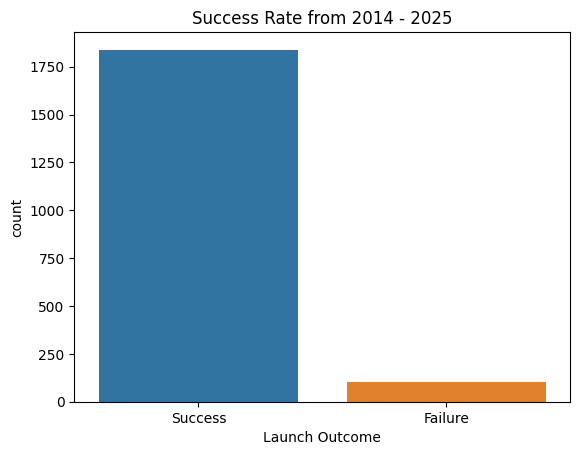

In [50]:
# Success vs Failures
ax = sns.countplot(data=launch_dataset, x="launch_outcome", hue="launch_outcome")
ax.set_xticklabels(["Success", "Failure"])
ax.legend_.remove()
plt.xlabel("Launch Outcome")
plt.title("Success Rate from 2014 - 2025")

plt.savefig(f"Images/launch_outcome_distribution.png", bbox_inches='tight')
plt.show()


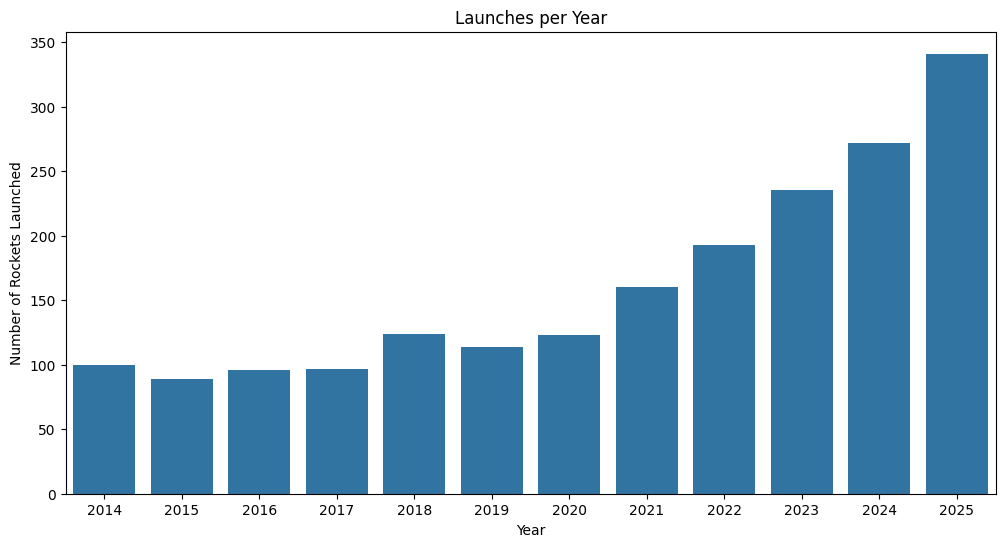

In [51]:
# Launches per Year
plt.figure(figsize=(12,6))

sns.countplot(data=launch_dataset, x="year")
plt.xlabel("Year")
plt.ylabel("Number of Rockets Launched")
plt.title("Launches per Year")

plt.savefig(f"Images/launches_per_year.png", bbox_inches='tight')
plt.show()


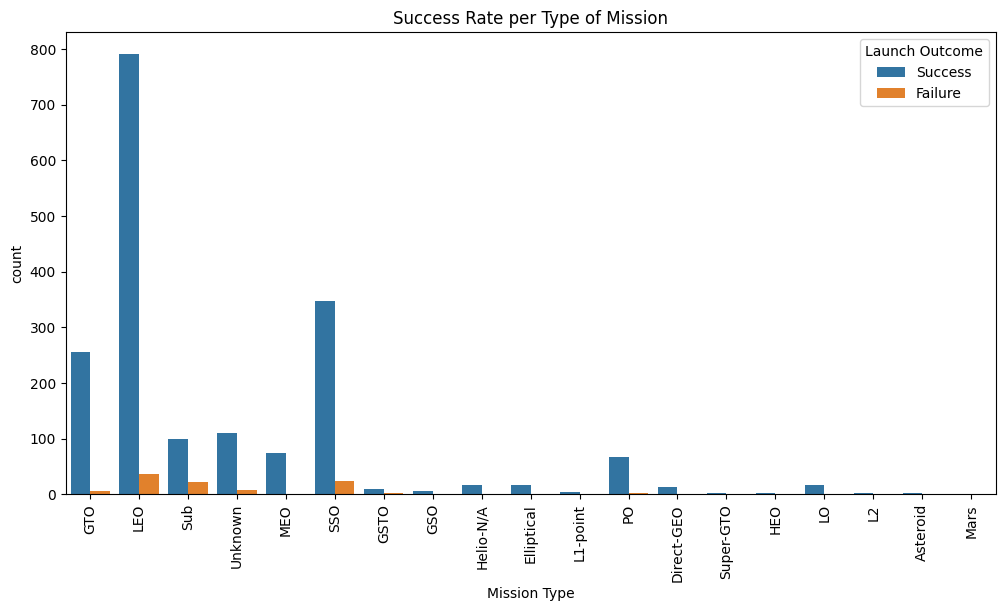

In [52]:
# Success Rate per Type of Mission
plt.figure(figsize=(12,6))

sns.countplot(data=launch_dataset, x="mission.orbit.abbrev", hue="launch_outcome")
plt.xticks(rotation=90)
plt.xlabel("Mission Type")
plt.title("Success Rate per Type of Mission")
plt.legend(title="Launch Outcome", labels=["Success", "Failure"])

plt.savefig(f"Images/success_rate_per_mission_type.png", bbox_inches='tight')
plt.show()


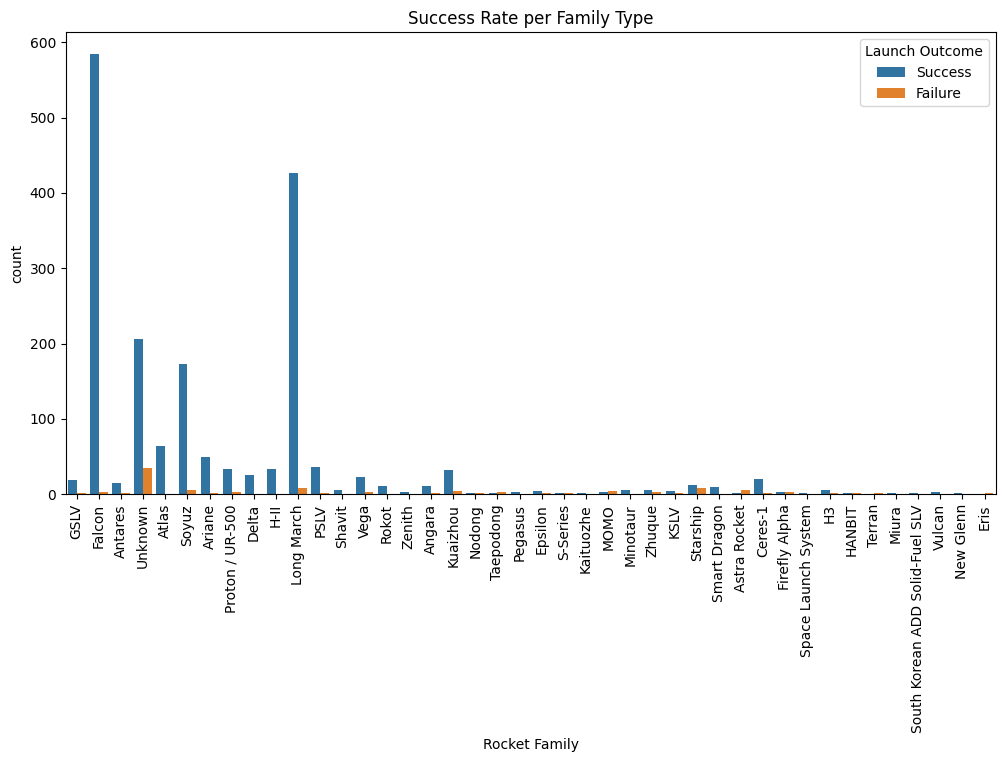

In [53]:
# Success Rate per Family Type
plt.figure(figsize=(12,6))

sns.countplot(data=launch_dataset, x="rocket.configuration.family", hue="launch_outcome")
plt.xticks(rotation=90)
plt.xlabel("Rocket Family")
plt.title("Success Rate per Family Type")
plt.legend(title="Launch Outcome", labels=["Success", "Failure"])

plt.savefig(f"Images/success_rate_per_family_type.png", bbox_inches='tight')
plt.show()


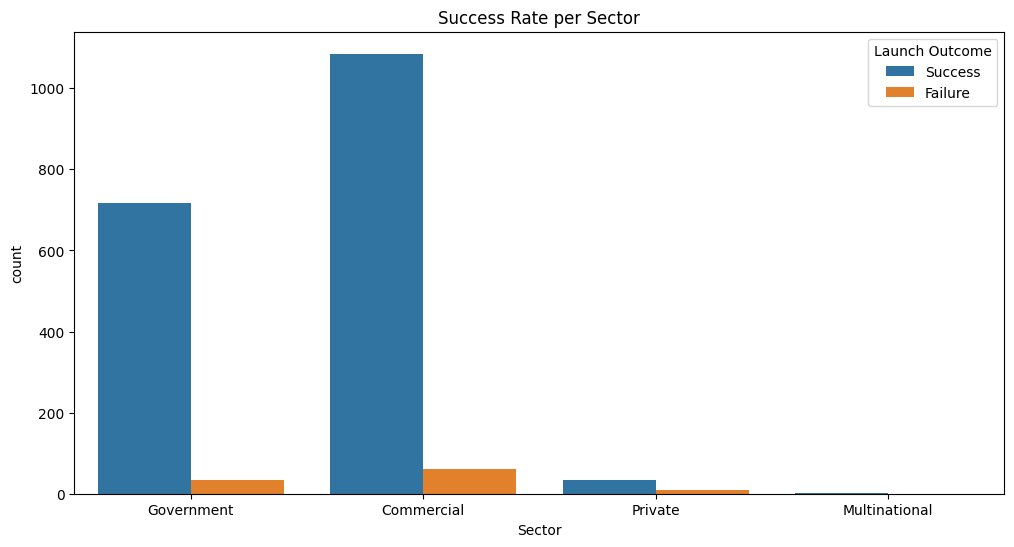

In [54]:
# Success Rate per Sector
plt.figure(figsize=(12,6))

sns.countplot(data=launch_dataset, x="launch_service_provider.type", hue="launch_outcome")
plt.xlabel("Sector")
plt.title("Success Rate per Sector")
plt.legend(title="Launch Outcome", labels=["Success", "Failure"])

plt.savefig(f"Images/success_rate_per_sector.png", bbox_inches='tight')
plt.show()


**Takeaways:** launch outcomes are heavily imbalanced (~95% success, ~5% failure/partial failure), which is why accuracy alone won't be a reliable metric later on. Launch cadence grows sharply from 2021 onward. GTO missions and rockets with an unrecorded ('Unknown') family show a visibly higher share of failures relative to their volume than LEO/SSO missions or established families like Falcon and Long March. Both are reasonable candidates for predictive signal. Government and Commercial launches dominate the dataset, with Private and Multinational launches too few to draw conclusions from.


## 1.5 Train/Test Split

Launches are split chronologically -- the oldest 70% for training, the newest 30% for testing -- rather than randomly, since the goal is to predict future launches from historical patterns. A random split would let future launches leak into training and inflate test performance.


In [55]:
# Sort values by chronological order
launch_dataset = launch_dataset.sort_values("window_start_date").reset_index(drop=True)

# 70/30 split
split_idx = int(len(launch_dataset) * 0.7)

# Training set (past)
X_train = launch_dataset.iloc[:split_idx].drop(columns=["launch_outcome", "window_start_date"])
y_train = launch_dataset.iloc[:split_idx]["launch_outcome"]

# Test set (future)
X_test = launch_dataset.iloc[split_idx:].drop(columns=["launch_outcome", "window_start_date"])
y_test = launch_dataset.iloc[split_idx:]["launch_outcome"]


In [56]:
# Check failure count in train and test set
print(f"Failures in Train: {y_train.sum()}")
print(f"Failures in Test: {y_test.sum()}")


Failures in Train: 86
Failures in Test: 19


## 1.6 Post-Split Feature Engineering

Everything from here on must be fit using the training set only, then applied identically to the test set -- handled by `engineer_post_split_features`, defined in section 1.1. This single call replaces what used to be ~8 near-duplicated cells (one set of transformations written out for `X_train`, then copy-pasted for `X_test`), so a future change can no longer accidentally apply to one split and not the other.


In [57]:
X_train_scaled, X_test_scaled = engineer_post_split_features(X_train, X_test)
X_train_scaled.head()


,orbital_launch_attempt_count,location_launch_attempt_count,pad_launch_attempt_count,agency_launch_attempt_count,orbital_launch_attempt_count_year,location_launch_attempt_count_year,pad_launch_attempt_count_year,agency_launch_attempt_count_year,pad.location.total_launch_count,pad.location.total_landing_count,...,"pad.location.name_Xichang Satellite Launch Center, People's Republic of China",pad.country_code_GUF,pad.country_code_IND,pad.country_code_IRN,pad.country_code_JPN,pad.country_code_KAZ,pad.country_code_NZL,pad.country_code_Other,pad.country_code_RUS,pad.country_code_USA
0,-0.144616,-0.834002,-0.822117,-1.032566,-1.242025,-0.775608,-0.554409,-0.687224,-0.866571,-0.587013,...,False,False,True,False,False,False,False,False,False,False
1,-0.143971,0.433458,-0.328138,-1.250756,-1.222396,-0.775608,-0.554409,-0.687224,0.907587,2.066637,...,False,False,False,False,False,False,False,False,False,True
2,-0.143327,-0.803414,-0.868719,-0.790132,-1.202768,-0.775608,-0.554409,-0.687224,-0.900828,-0.587013,...,False,False,False,False,False,False,False,False,False,True
3,-3.593916,-0.814885,-0.607749,-1.097215,-1.261653,-0.775608,-0.554409,-0.687224,-0.897222,-0.587013,...,False,False,False,False,False,False,False,False,False,True
4,-3.593916,-0.812973,-0.598429,-1.089134,-1.261653,-0.658236,-0.411336,-0.628549,-0.897222,-0.587013,...,False,False,False,False,False,False,False,False,False,True


In [58]:
print(X_train_scaled.isna().sum().to_string())
print(X_train_scaled.dtypes.to_string())


orbital_launch_attempt_count                                                          0
location_launch_attempt_count                                                         0
pad_launch_attempt_count                                                              0
agency_launch_attempt_count                                                           0
orbital_launch_attempt_count_year                                                     0
location_launch_attempt_count_year                                                    0
pad_launch_attempt_count_year                                                         0
agency_launch_attempt_count_year                                                      0
pad.location.total_launch_count                                                       0
pad.location.total_landing_count                                                      0
pad.total_launch_count                                                                0
pad.orbital_launch_attempt_count

## 2.0 Modelling

Three classifiers are compared: Logistic Regression as an interpretable baseline, Random Forest, and XGBoost. Since launch failures make up only ~5% of the data (section 1.3), plain accuracy is misleading -- a model that always predicts "success" would already score ~95%. ROC AUC, average precision, and PR AUC are reported alongside it for a fairer picture, and `class_weight`/`scale_pos_weight` are used during training to counteract the imbalance.


In [59]:
def evaluate_classifier(model_name, y_true, y_pred, y_prob):
    """
    Print confusion matrix, classification report, accuracy, ROC AUC,
    average precision, and PR AUC for a fitted classifier.

    PR AUC and average precision are included because launch outcomes
    are heavily imbalanced (~95% success / 5% failure), which makes
    precision-recall metrics more informative than accuracy or ROC AUC
    alone.

    Parameters
    ----------
    model_name : str
        Label used in the printed header (e.g. "Logistic Regression").
    y_true : array-like
        Ground-truth binary labels.
    y_pred : array-like
        Predicted binary labels.
    y_prob : array-like
        Predicted probabilities for the positive (failure) class.
    """
    print(f"=== {model_name} ===")
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    print(f"\n{model_name} Accuracy:", accuracy_score(y_true, y_pred))
    print("ROC AUC:", roc_auc_score(y_true, y_prob))
    print("Average Precision:", average_precision_score(y_true, y_prob))

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    pr_auc = auc(recall, precision)
    print(f"PR AUC Score: {pr_auc}")


def plot_confusion_matrix(y_true, y_pred, model_name):
    """
    Plot a green-shaded confusion matrix with Success/Failure labels.
    """
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Success", "Failure"])
    disp.plot(cmap="Greens")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.savefig(f"Images/{model_name}_confusion_matrix.png", bbox_inches='tight')
    plt.show()


def plot_feature_importance(importances, feature_names, model_name, top_n=25):
    """
    Print every feature's importance score (sorted, descending) and plot
    a horizontal bar chart of the top `top_n` features.

    Parameters
    ----------
    importances : array-like
        Feature importances from a fitted tree-based model.
    feature_names : array-like
        Column names matching `importances`, in the same order.
    model_name : str
        Label used in the plot title.
    top_n : int, default 25
        Number of top features to plot.

    Returns
    -------
    pandas.Series
        All feature importances, sorted descending.
    """
    feature_scores = pd.Series(importances, index=feature_names).sort_values(ascending=False)
    print(feature_scores)

    top_features = feature_scores.head(top_n)
    plt.figure(figsize=(10, 8))
    sns.barplot(x=top_features.values, y=top_features.index)
    plt.xlabel("Feature Importance")
    plt.ylabel("Features")
    plt.title(f"Feature Importance of {model_name}")
    plt.savefig(f"Images/{model_name}_feature_importance.png", bbox_inches='tight')
    plt.show()

    return feature_scores


## 2.1 Logistic Regression

A regularized logistic regression as an interpretable baseline, with `class_weight="balanced"` to counteract the 95/5 class imbalance.


In [60]:
logit = LogisticRegression(
    solver="lbfgs",
    class_weight="balanced",                   # Adjusts weights inversely proportional to class frequencies
    C=10.0,                                     # Inverse of regularization strength
    warm_start=False,
    penalty="l2",
    max_iter=1000,                              # Maximum iterations for convergence
    random_state=111
)

logit.fit(X_train_scaled, y_train)

y_pred_logit = logit.predict(X_test_scaled)
y_prob_logit = logit.predict_proba(X_test_scaled)[:, 1]

evaluate_classifier("Logistic Regression", y_test, y_pred_logit, y_prob_logit)


=== Logistic Regression ===

Confusion Matrix:
[[531  34]
 [  8  11]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.94      0.96       565
           1       0.24      0.58      0.34        19

    accuracy                           0.93       584
   macro avg       0.61      0.76      0.65       584
weighted avg       0.96      0.93      0.94       584


Logistic Regression Accuracy: 0.928082191780822
ROC AUC: 0.8833721471821145
Average Precision: 0.23312947360464154
PR AUC Score: 0.20589455886028737


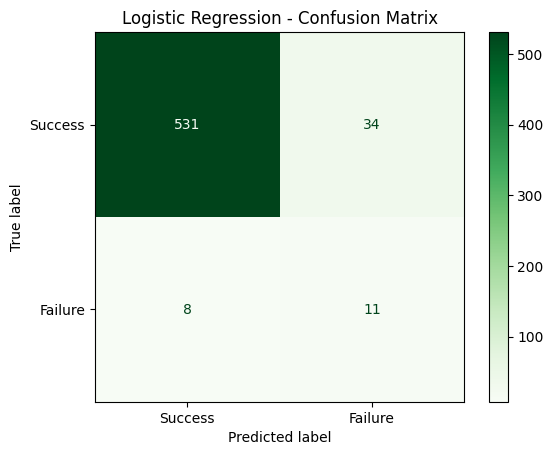

In [61]:
plot_confusion_matrix(y_test, y_pred_logit, "Logistic Regression")


## 2.2 Random Forest

A shallow, bagged ensemble (`max_depth=4`, 500 trees), again with `class_weight="balanced"` to counteract the class imbalance.


In [62]:
rf = RandomForestClassifier(
    n_estimators=500,                        # Number of trees
    class_weight="balanced",                 # Adjusts for class imbalance
    random_state=111,
    max_depth=4,
    bootstrap=True,
    oob_score=True
)

rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)
y_prob_rf = rf.predict_proba(X_test_scaled)[:, 1]

evaluate_classifier("Random Forest", y_test, y_pred_rf, y_prob_rf)


=== Random Forest ===

Confusion Matrix:
[[519  46]
 [  5  14]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.92      0.95       565
           1       0.23      0.74      0.35        19

    accuracy                           0.91       584
   macro avg       0.61      0.83      0.65       584
weighted avg       0.97      0.91      0.93       584


Random Forest Accuracy: 0.9126712328767124
ROC AUC: 0.8812296227293899
Average Precision: 0.30570804076805397
PR AUC Score: 0.27630935401284734


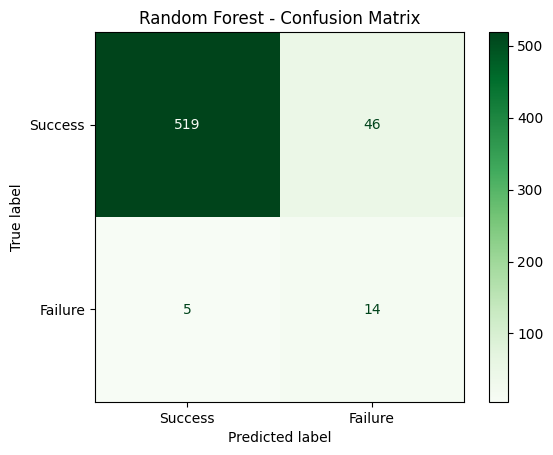

In [63]:
plot_confusion_matrix(y_test, y_pred_rf, "Random Forest")


pad.orbital_launch_attempt_count                     0.075637
pad.total_launch_count                               0.065712
log_agency_launches                                  0.065154
log_pad_launches                                     0.064162
pad_launch_attempt_count                             0.061324
                                                       ...   
launch_service_provider.name_Russian Space Forces    0.000125
rocket.configuration.family_GSLV                     0.000109
launch_service_provider.type_Private                 0.000074
mission.type_Other                                   0.000011
launch_service_provider.type_Other                   0.000010
Length: 108, dtype: float64


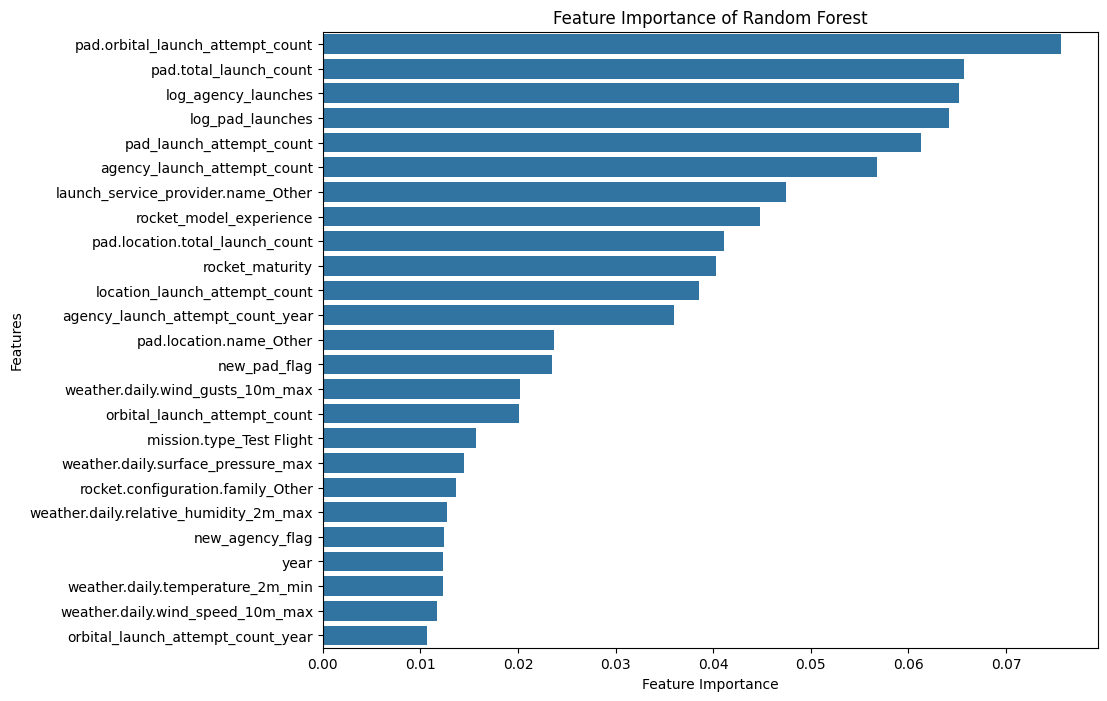

In [64]:
rf_feature_scores = plot_feature_importance(rf.feature_importances_, X_train_scaled.columns, "Random Forest")


## 2.3 XGBoost

A gradient-boosted ensemble with manually tuned regularization (`reg_alpha`, `reg_lambda`, `gamma`) and `scale_pos_weight` to counteract the class imbalance, using PR-AUC as the training evaluation metric since it's more informative than accuracy here.


In [65]:
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=500,                    # Number of boosting rounds
    learning_rate=0.02,
    max_depth=4,
    min_child_weight=3,                  # Minimum sum of instance weight in a leaf
    subsample=0.8,
    colsample_bytree=0.7,
    reg_alpha=3,
    reg_lambda=7,
    gamma=1.5,
    scale_pos_weight=scale_weight,       # Adjusts for class imbalance
    objective='binary:logistic',
    eval_metric="aucpr",                 # Evaluation metric for imbalanced data
    random_state=111
)

xgb.fit(X_train_scaled, y_train)

y_prob_xgb = xgb.predict_proba(X_test_scaled)[:, 1]

# Lower the decision threshold from the default 0.5 to 0.2: trades some
# precision for recall on the minority "failure" class, which matters
# more here than overall accuracy.
y_pred_xgb = (y_prob_xgb >= 0.2).astype(int)

evaluate_classifier("XGBoost", y_test, y_pred_xgb, y_prob_xgb)


=== XGBoost ===

Confusion Matrix:
[[486  79]
 [  3  16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92       565
           1       0.17      0.84      0.28        19

    accuracy                           0.86       584
   macro avg       0.58      0.85      0.60       584
weighted avg       0.97      0.86      0.90       584


XGBoost Accuracy: 0.8595890410958904
ROC AUC: 0.8992081974848626
Average Precision: 0.3618286053554424
PR AUC Score: 0.35110205126415633


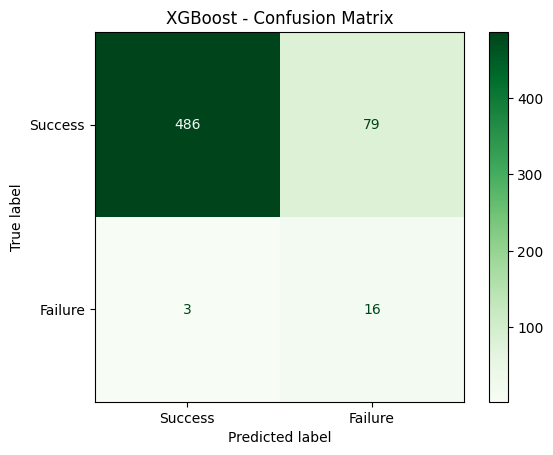

In [66]:
plot_confusion_matrix(y_test, y_pred_xgb, "XGBoost")

pad.total_launch_count                                                           0.060501
pad.orbital_launch_attempt_count                                                 0.053434
launch_service_provider.name_Other                                               0.045616
pad.location.name_Baikonur Cosmodrome, Republic of Kazakhstan                    0.023996
pad.location.name_Other                                                          0.022906
                                                                                   ...   
pad.location.name_Kennedy Space Center, FL, USA                                  0.000000
pad.location.name_Xichang Satellite Launch Center, People's Republic of China    0.000000
pad.location.name_Tanegashima Space Center, Japan                                0.000000
pad.location.name_Vandenberg SFB, CA, USA                                        0.000000
pad.location.name_Vostochny Cosmodrome, Siberia, Russian Federation              0.000000
Length: 10

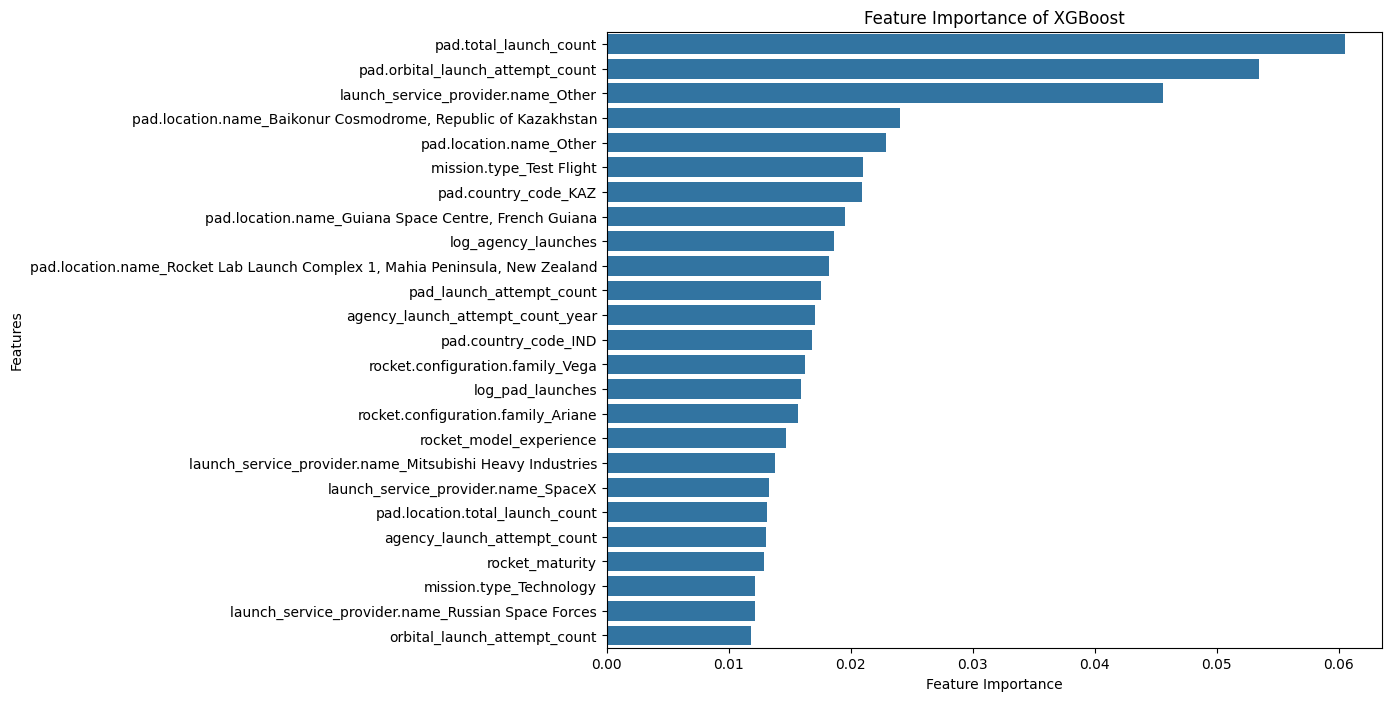

In [67]:
xgb_feature_scores = plot_feature_importance(xgb.feature_importances_, X_train_scaled.columns, "XGBoost")

### Future Improvements:
Introduce a validation set to enable techniques such as early stopping in XGBoost.

Perform hyperparameter tuning.

### Code Structure Update

Following feedback on the original submission, the pipeline was reorganized: steps 1-3 (data collection and cleaning) were converted from notebooks into standalone scripts sharing a common `data_utils.py` helper module, and the post-split feature engineering in this notebook -- previously duplicated for the train and test sets -- was consolidated into the `engineer_post_split_features` function defined in section 1.1.
